# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')#completa el código
usage = pd.read_csv('/datasets/usage.csv')#completa el código

In [3]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head()
# mostrar las primeras 5 filas de users

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head()# mostrar las primeras 5 filas de usage

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
users.info()# inspección de users con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


**Conclusiones** 

En el DataFrame plans podemos observar que tiene 8 columnas y tan solo 2 registros, 7 columnas son númericas menos la primera "plan_name" que es tipo objet

En el DataFrame users observamos que las columnas "reg_date" y "churn_date" son tipo object pero deberían ser tipo datetime, cuenta también con 8 columnas y 4000 registros.

En el DataFrame usage encontramos solo 6 columnas pero tiene 40000 registros, también tiene una columna (date) que debería ser datetime pero es objet.

---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())# Cantidad de valores nulos)
print(users.isna().mean())# Proporción de valores nulos)

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
print(usage.isna().sum())# cantidad de nulos para usage
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?

  En el DataFrame de users de las 8 columnas solo 2 presentan valores ausentes (city y churn_date), city muestra 469 valores nulos que representan el 11.72% del total de registros, en la columna de churn_date hay 3534 registros nulos (88.35% del total de registros).

  En el DataFrame usage se visualizan 50 valores nulos para "date" lo que representa un 0.001% de los datos, 22076 valores nulos en duration (55.19%) y 17896 valores nulos en lenth, lo que representa el 44.74% del total de los datos.

  
- Indica qué harías: ¿imputar, eliminar, ignorar?

   users.city: Recomiendo hacer una investiación mas profunda para entender si son ciudades pequeñas, error humano, o algún otro tipo de razón que explique ese porcentaje sin determinar. --> Imputar

  
    users.churn_date: Muestra que son usuarios que no se han dado de baja, por lo que no representa un error, sino una realidad normal de negocio. --> Ignorar

  
    usage.date: Se recomienda eliminar estos registros ya que no tendrán un impacto significativo para el análisis. --> Eliminar

  
    usage.duration y usage.length: Es el comportamiento normal de la metrica ya que en este caso indica el detalle de las 2 opciones de servicio, si no aplica uno tiene que ser el otro, la diferencia con el total de los datos es de 0.07%. --> Ignorar

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
users["age"].describe()

count    4000.000000
mean       33.739750
std       123.232257
min      -999.000000
25%        32.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

- La columna `user_id` no la tendré en cuenta ya que considero que no aportará ningúna conclusión relevante al análisis de datos mas allá de una númericación que empieza desde 10000.
- La columna `age` por el contrario aporta información relevante ya que visualizamos sentinels de -999 en el valor min del resumen estadístico, lo que aumenta la desviación estandar, pero por lo demás se ve muy centrada y sin sesgos aparentes.

In [13]:
columnas_usage = ['duration', 'length']
display(usage[columnas_usage].describe())
# explorar columnas numéricas de usage

,duration,length
count,17924.000000,22104.000000
mean,5.202237,52.127398
std,6.842701,56.611183
min,0.000000,0.000000
25%,1.437500,37.000000
50%,3.500000,50.000000
75%,6.990000,64.000000
max,120.000000,1490.000000


- Las columnas `id` y `user_id`no la tendré en cuenta ya que considero que no aportará ningúna conclusión relevante al análisis de datos mas allá de una númericación secuencial de las 40mil filas.

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
display(users[columnas_user].describe())
users[columnas_user].value_counts()

,city,plan
count,3531,4000
unique,7,2
top,Bogotá,Basico
freq,808,2595


city      plan   
Bogotá    Basico     522
CDMX      Basico     474
Medellín  Basico     398
GDL       Basico     298
Bogotá    Premium    286
MTY       Basico     275
Cali      Basico     262
CDMX      Premium    256
Medellín  Premium    218
Cali      Premium    162
GDL       Premium    152
MTY       Premium    132
?         Basico      65
          Premium     31
dtype: int64

- La columna `city` muestra 3531 registros con valor, aunque se aprecian valores "?" tanto para plan basico como premium, muestra también 7 valores unicos y Bogotá es el top con 808 registros sumando basico y premium.
- La columna `plan` muestra excelente estandarización, solo refleja 2 valores únicos (Basico y Premium) siendo basico el top con 2595 registros.

In [15]:
# explorar columna categórica de usage
display(usage['type'].describe())
usage["type"].value_counts()# completa el código

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` muestra dos únicos valores que cubren los 40mil registros, siendo text el top con 22092 registros, el restante corresponden al valor "call", no hay presencia de nulos.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?

    users.age: Hay presencia de sentinels (-999), se recomienda normalizar aplicando la mediana!.
  
    user.city: Hay presencia de valores nulos, se debe profundizar para encontrar la razón, también hay valores inválidos ("?"), al representar menos de un 5% del dataframe se recomienda eliminarlos del análisis actual pero tomar acción para determinar una mejor forma en la obtención de datos a futuro.
 

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users["reg_date"], errors = "coerce")
users["year"] = users["reg_date"].dt.year# completa el código

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage["date"], errors = "coerce")
usage["year"] = usage["date"].dt.year# completa el código

In [18]:
# Revisar los años presentes en `reg_date` de users
users["year"].value_counts()

2024    1330
2023    1316
2022    1314
2026      40
Name: year, dtype: int64

En `reg_date`, decidí crear una nueva columna de nombre "year" para extraer solo la información del año, después de verificar los datos de la columna encontre 40 registros inválidos ya que muestran como año "2026", una fecha imposible si tenemos en cuenta que el análisis se realiza con datos unicamente **hasta** 2024.

In [19]:
usage["year"].value_counts()# Revisar los años presentes en `date` de usage


2024.0    39950
Name: year, dtype: int64

En `date`, nuevamente decidí crear una nueva columna en este dataframe de nombre "year", se observa que todos los registros pertenecen al 2024 y también se reflejan los 50 valores nulos que habiamos identificado antes.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)

    Para los 40 registros con valor users.year = 2026 sugiero eliminarlos para este análisis y no entrar en investigaciones, representas solo el 1% de los datos y no tendrá un impacto relevante en las conclusiones.

  En el caso de los 50 valores nulos en usage.year mi recomendación es normalizarlos con el unico valor presente en esta columna (2024) ya que seguramente fue un olvido humnano.


---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users["age"].median()
users['age'] = users["age"].replace(-999, age_mediana)

# Verificar cambios
#users['age'].describe()
users["age"].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [23]:
users["city"] = users["city"].replace("?", pd.NA)# Reemplazar ? por NA en city


users["city"].value_counts()
# Verificar cambios

Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [24]:
users["year"] = users["year"].replace(2026, pd.NA)# Marcar fechas futuras como NA para reg_date


users["year"].value_counts()# Verificar cambios

2024    1330
2023    1316
2022    1314
Name: year, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [25]:
usage["duracion_faltante"] = usage["duration"].isna()
usage.groupby("type")["duracion_faltante"].mean()# Verificación MAR en usage (Missing At Random) para duration


type
call    0.000000
text    0.999276
Name: duracion_faltante, dtype: float64

In [26]:
usage["extension_faltante"] = usage["length"].isna()
usage.groupby("type")["extension_faltante"].mean()# Verificación MAR en usage (Missing At Random) para length


type
call    0.99933
text    0.00000
Name: extension_faltante, dtype: float64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

Los datos faltantes observados en el DataFrame usage en las columnas "duration" y "length" indican un tipico comportamiento **MAR** ya que según el tipo de servicio le corresponde un valor en "duration" **O** en "length", los datos muestran claramente que cuando es tipo llamada la columna "length" es nula en mas de un 99.9% mientras que opuestamente el tipo text es 99.9% nulo en la columna "duration".
Por esta razón no se dará tratamiento a los datos nulos y se conservarán tal cual por tratarse del comportamiento natural del negocio.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [27]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg(
    cant_mensajes = ("is_text", "sum"),
    cant_llamadas = ("is_call", "sum"),
    cant_minutos_llamada = ("duration", "sum")
).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [28]:
# Renombrar columnas

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [29]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on = "user_id", how = "inner")
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,year,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,2022,7,3,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,2022,5,10,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,2022,5,2,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,2022,11,3,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,2022,4,3,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [30]:
# Filtrar para obtener solo usuarios durante el 2024
user_profile_2024 = user_profile[user_profile["year"] == 2024].copy()
user_profile_2024["year"].value_counts()

2024    1330
Name: year, dtype: int64

In [31]:
# Resumen estadístico de las columnas numéricas[columnas_numericas].describe()
columnas_numericas = ["age", "cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]

user_profile_2024[columnas_numericas].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,1330.000000,1330.000000,1330.000000,1330.000000
mean,48.414286,5.500000,4.557143,24.126669
std,17.963443,2.382293,2.140329,19.458620
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.332500
50%,48.000000,5.000000,4.000000,20.325000
75%,64.000000,7.000000,6.000000,32.542500
max,79.000000,16.000000,13.000000,155.690000


In [32]:
# Distribución porcentual del tipo de plan
user_profile_2024["plan"].value_counts(normalize = True) * 100


Basico     65.639098
Premium    34.360902
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

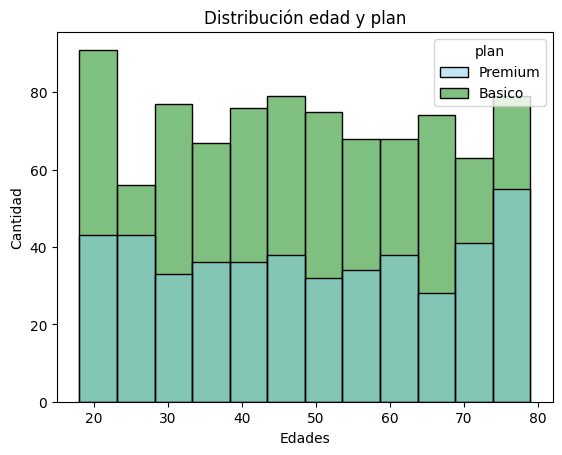

In [48]:
# Histograma para visualizar la edad (age)
sns.histplot(data = user_profile_2024, x = "age", hue = "plan", palette = ["skyblue", "green"])
plt.title("Distribución edad y plan")
plt.xlabel("Edades")
plt.ylabel("Cantidad")
plt.show()

💡Insights: 
- Se puede visualizar una distribución simétrica con 2 picos que sobresalen justo al inicio y fin del histograma, indicando que hay un aumento en las edades entre los 18-23 años y los 74-79 años.
- Por otro lado se observa como este último grupo (74-79 años) tienen preferencia por el plan Premium.

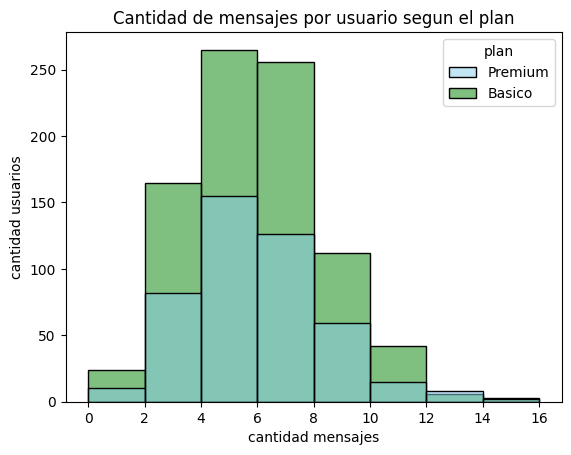

In [34]:
# Histograma para visualizar la cant_Mensajes
sns.histplot(data = user_profile_2024, x = "cant_mensajes", bins = 8, hue = "plan", palette = ["skyblue", "green"])
plt.title("Cantidad de mensajes por usuario segun el plan")
plt.xlabel("cantidad mensajes")
plt.ylabel("cantidad usuarios")
plt.show()

💡Insights: 
- El histograma muestra un ligero sesgo a la derecha indicando que la mayoría de datos se concentran en cantidades mas bajas, puntualmente se observa una gran concentración entre los 2 y los 8 mensajes. Unos pocos usuarios que envian mas de 12 mensajes halan el promedio. El registro mas alto lo tiene el intervalo de usuarios que envian 4-5 mensajes.

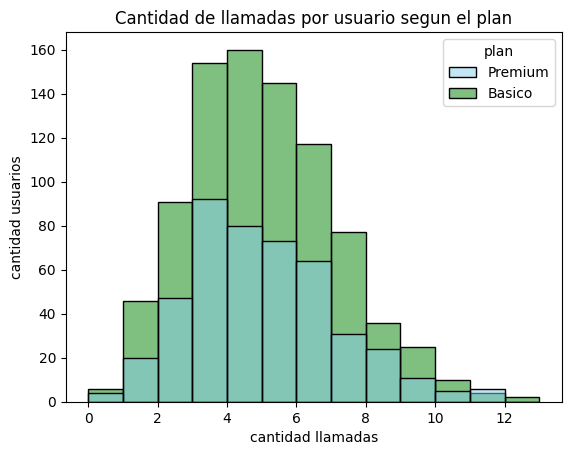

In [35]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data = user_profile_2024, x = "cant_llamadas", bins = 13, hue = "plan", palette = ["skyblue", "green"])
plt.title("Cantidad de llamadas por usuario segun el plan")
plt.xlabel("cantidad llamadas")
plt.ylabel("cantidad usuarios")
plt.show()

💡Insights: 
- La distribución de los datos es simetrica con una pequeña cola a la derecha, se puede observar una pequeña diferencia que indica que las llamadas del plan premium superan por poco a las del plan basico. Muestra su mayor concentración en los usuarios que hacen entre 4 y 5 llamadas.

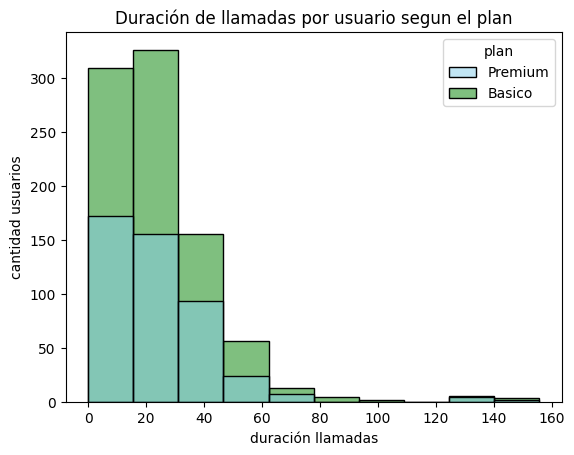

In [36]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data = user_profile_2024, x = "cant_minutos_llamada", bins = 10, hue = "plan", palette = ["skyblue", "green"])
plt.title("Duración de llamadas por usuario segun el plan")
plt.xlabel("duración llamadas")
plt.ylabel("cantidad usuarios")
plt.show()

💡Insights: 
- En el historama de la duración de las llamadas si se observa un fuerte sesgo a la derecha, aunque la mayoria de usuarios suele tardar no mas de 35 minutos por llamada, hay pocos usuarios que muestran duración de llamadas alcanzando inclusive las 2 o 2.5 horas por llamada, por este motivo no se recomienda usar el promedio ya que los outliers distorsionan mucho la realidad del comportamiento en la duración de las llamadas, es mas recomendable usar la mediana!, Nuevamente se observa un valor similar para ambos tipos de plan.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

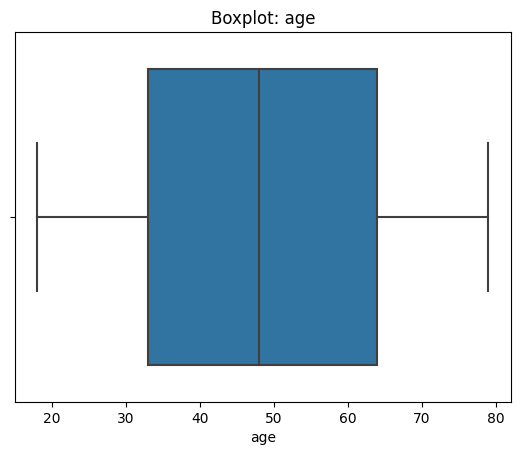

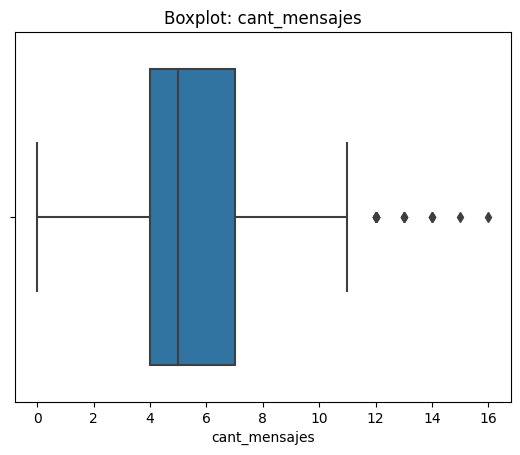

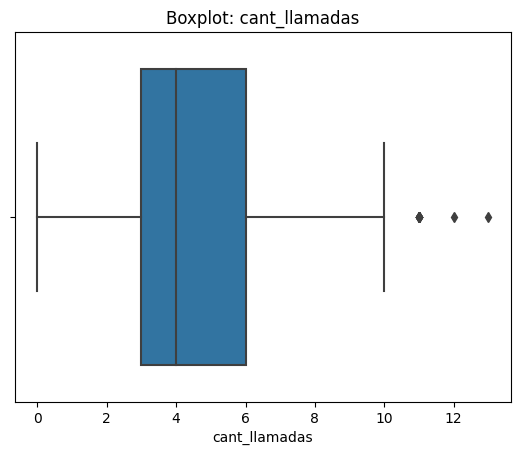

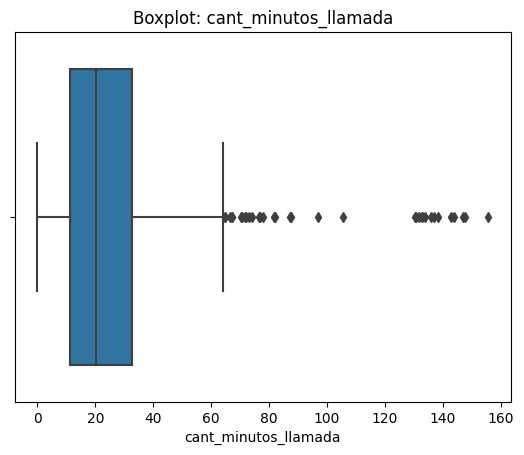

In [37]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data = user_profile_2024, x = col)
    plt.title(f'Boxplot: {col}')
    plt.show()

💡Insights: 
- Age: En la columna de edad no se presenta ningún outlier, de hecho tiene una distribución simetrica exacta según el boxplot.
- cant_mensajes: En la columna cantidad de mensajes si se evidencian outliers entre los valores 11 y 16 mensajes.
- cant_llamadas: En la columna cantidad de llamadas también se observan outliers a la derecha en un intervalo aproximado entre las 11 y las 13 llamadas
- cant_minutos_llamada: Finalmente en la columna cantidad de minutos por llamada encontramos la mayor dispersión de datos al observar una larga cola a la derecha  con valores muy altos por encima del límite superior.

In [38]:
# Calcular límites con el método IQR
columnas_limites = ["cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]

for col in columnas_limites:
    q1 = user_profile_2024[col].quantile(0.25)
    q3 = user_profile_2024[col].quantile(0.75)
    IQR = q3 - q1
    limite_superior = q3 + 1.5 * IQR
    print(col)
    print("limite superior: ", limite_superior)

cant_mensajes
limite superior:  11.5
cant_llamadas
limite superior:  10.5
cant_minutos_llamada
limite superior:  64.35749999999999


In [39]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
      Yo recomendaría mantener los outliers ya que no representan valores imposibles y marcan mas el tipo de consumo de super cliente, al no estar ampliamente alejados del límite superior yo aplicaría winsorización.
- cant_llamadas: mantener o no outliers, porqué?
      Como en el caso de los mensajes para las llamadas tambien mantendría los outliers por la misma razçon y aplicando el mismo método de winsorización.
- cant_minutos_llamada: mantener o no outliers, porqué?
      En el caso de la duración de las llamadas el comportamiento cambia ya que hay varios valores muy por encima del límite superior, para este caso siento que winsorizar no es lo mas conveniente ya que se pierde información real de super clientes que si generan un consumo atípico. Aquí simplemente usaría el mètodo keep.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [40]:
# Crear columna grupo_uso


def definir_uso(row):
    if row["cant_mensajes"] < 5 and row["cant_llamadas"]< 5:
        return "Bajo uso"
    elif row["cant_mensajes"] < 10 and row["cant_llamadas"]< 10:
        return "Uso medio"
    else:
        return "Alto uso"

user_profile_2024["grupo_uso"] = user_profile_2024.apply(definir_uso, axis = 1)

In [41]:
# verificar cambios
user_profile_2024.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,year,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
2665,12666,Mateo,Garcia,20.0,Cali,2024-01-01 00:00:00.000000000,Premium,NaN,2024,13,3,11.50,Alto uso
2666,12667,Carlos,Gomez,72.0,Cali,2024-01-01 06:34:17.914478624,Premium,NaN,2024,3,7,33.27,Uso medio
2667,12668,Ana,Torres,21.0,CDMX,2024-01-01 13:08:35.828957240,Basico,NaN,2024,5,7,87.56,Uso medio
2668,12669,Sofia,Garcia,58.0,CDMX,2024-01-01 19:42:53.743435864,Basico,NaN,2024,4,5,27.62,Uso medio
2669,12670,Ana,Garcia,54.0,MTY,2024-01-02 02:17:11.657914480,Premium,NaN,2024,9,4,31.90,Uso medio


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [42]:
# Crear columna grupo_edad
def segmentar_edad(row):
    if row["age"] < 30:
        return "Joven"
    elif row["age"] < 60:
        return "Adulto"
    else:
        return "Adulto Mayor"

user_profile_2024["grupo_edad"] = user_profile_2024.apply(segmentar_edad, axis = 1)
    

In [43]:
# verificar cambios
user_profile_2024.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,year,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
2665,12666,Mateo,Garcia,20.0,Cali,2024-01-01 00:00:00.000000000,Premium,NaN,2024,13,3,11.50,Alto uso,Joven
2666,12667,Carlos,Gomez,72.0,Cali,2024-01-01 06:34:17.914478624,Premium,NaN,2024,3,7,33.27,Uso medio,Adulto Mayor
2667,12668,Ana,Torres,21.0,CDMX,2024-01-01 13:08:35.828957240,Basico,NaN,2024,5,7,87.56,Uso medio,Joven
2668,12669,Sofia,Garcia,58.0,CDMX,2024-01-01 19:42:53.743435864,Basico,NaN,2024,4,5,27.62,Uso medio,Adulto
2669,12670,Ana,Garcia,54.0,MTY,2024-01-02 02:17:11.657914480,Premium,NaN,2024,9,4,31.90,Uso medio,Adulto


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

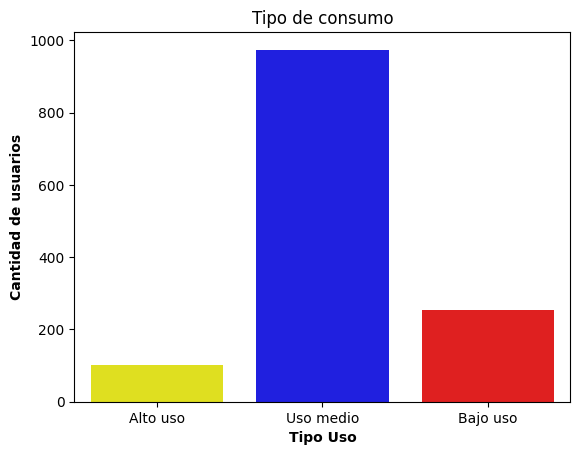

In [44]:
# Visualización de los segmentos por uso
sns.countplot(data = user_profile_2024, x = "grupo_uso", palette = ["yellow", "blue", "red"])
plt.title("Tipo de consumo")
plt.xlabel("Tipo Uso", fontweight='bold')
plt.ylabel("Cantidad de usuarios", fontweight='bold')
plt.show()

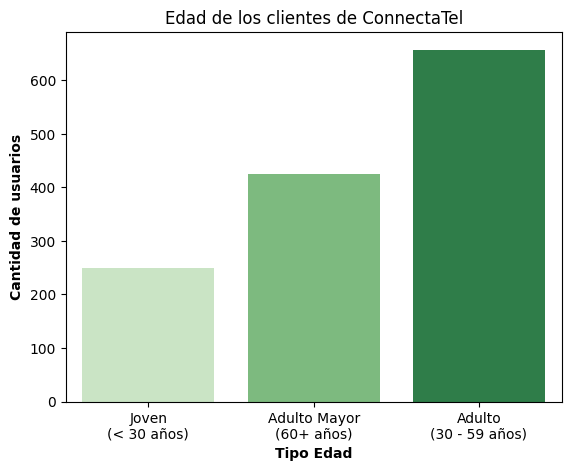

192

In [45]:
# Visualización de los segmentos por edad
sns.countplot(data = user_profile_2024, x = "grupo_edad", palette = "Greens")
plt.title("Edad de los clientes de ConnectaTel")
plt.xticks(
    ticks=[0, 1, 2], 
    labels=["Joven\n(< 30 años)", "Adulto Mayor\n(60+ años)", "Adulto\n(30 - 59 años)"],
)
plt.xlabel("Tipo Edad", fontweight='bold')
plt.ylabel("Cantidad de usuarios", fontweight='bold')
plt.show()

user_profile_2024["city"].isna().sum()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
Luego de realizar una exploración de los datos encontré varios problemas de calidad, los detallo a continuación:

        - Tipos de datos: De los 3 DataFrame 2 presentaban datos de fecha como tipo objet.

           - DataFrame Users: columnas reg_date y churn_date.
           - DataFrame Usage: columna date.

        - Valores nulos: En 2 de los 3 DataFrame se evidenciaron valores nulos en diferentes columnas.

            - DataFrame Users: Columna city con 565 valores nulos que representan el 14.12% de los valores totales, columna churn_date con 3534 valores nulos que representan el 88.35% de los valores totales.
            - DataFrame Usage: Columna date con 50 valores nulos que representan el 0.12% de los valores totales, duration con 22076 valores nulos que representan el 55.19% de los valores totales, length con 17896 valores nulos que representan el 44.74% de los valores totales.


        - Sentinels: Encontré 3 tipos de sentinels que requerían atención para el análisis de datos.

            - DataFrame Users: En la columna age encontré valores imposibles (-999) que distorionaban el análisis, en la columna city habia 96 valores "?".
            - DataFrame Usage: En la columna date, encontré valores imposible teniendo en cuenta que el contexto nos daba 2024 como la fecha máxima.


        - 

Las acciones tomadas para limpiar y organizar los dataframes y entregar mayor calidad en el análisis de datos:
Se creo una nueva columna en los dataframes users y usage llamada year para extraer el año de las fechas de inscripción y de uso de los servicios.

        - Tipo de datos: Para las 3 columnas implicadas se realizo cambio de tipo de datos de objet a datetime.

        - Valores nulos: Los valores nulos siguen presentes en la columna city, en una ampliación del análisis se podría investigar en que casos se usa el valor "?", o si existe una directriz para dejar el campo vacio.
                        Los 50 valores nulos en la fecha de usage se eliminaron con la filtración por año 2024
                        Los valores nulos en la columnas duration y length se mantienen ya que identificamos que son tipo MAR y corresponde al comportamiento real de las métricas

        - Sentinels: Para los valores -999 se reemplazaron por la mediana.
                    En la columna city los valores "?" fueron reemplazados por valores NA
                    En la columna year se reemplazaron los 40 valores de 2026 por valores NA.

🔍 **Segmentos por Edad**
Después de segmentar los usuarios por su edad establecemos lo siguiente:

    - En terminos generales la distribución del plan premium y básico esta distrbuido de forma uniforme entre las diferentes edades, mostrando como la anomalía mas notable la diferencia marcada en el rango de edad de 24-28 años donde si se ve una preferencia por el plan premium.

    - También establecí 3 grupos definidos para categorizar la edad de los usuarios (Joven, Adulto, Adulto Mayor) y se observa que la proporción de adultos es casi la suma de jovenes y adultos mayores.


📊 **Segmentos por Nivel de Uso**
De la misma manera segmentamos el uso de los servicios de ConnectaTel para comprender mejor las preferencias y consumo de los clientes.

    - Para el servicio de mensajes encontré un comportamiento simetrico con una ligera cola hacia la derecha que muestra a algunos usuarios haciendo un uso relativamente inusual y mayor al de la mayoría de usuarios, ya que si bien el promedio usan entre 5 y 5.5 mensajes hay otros usuarios que incluso han llegado a los 16 mensajes.

    - En el servicio de llamadas el comportamiento es muy parecido a los mensajes, aquí el promedio esta en 4.5 mientras que la mediana se observa en 4, nuevamente hay algunos datos atípicos que sesgan a la derecha pero sin que sea una tendencia demasiado marcada, en este caso el valor máximo esta en 13 llamadas.

    - En segmento de duración de llamadas si observamos un sesgo a la derecha importante, donde encontré que el 75% de los valores estan por debajo de 33 minutos, sin embaro el valor máximo se aleja casi 5 veces el valor del q3, marcando 155.69 minutos siendo la llamada mas larga, en este segmento se observan muchos mas outliers que en los otros dos segmentos.

    - En terminos generales podemos determinar que la enorme mayoría de usuarios tienen un tipo de uso medio de los servicios comparado con el uso alto y bajo.


➡️ Esto sugiere que ...

    - ConnectaTel debe aprovechar los segmentos de edades de adultos y adultos mayores ya que al tener en terminos generales mayor capacidad adquisitiva suelen vincularse mas con un plan pago fijo que las personas mas jovenes.

    - Los sementos de llamadas y mensajes muestran un comportamiento general parecido ya que no destaca mucho el uno del otro, por lo que la atención y el esfuerzo debe permanecer para ambos segmentos.

    - Revisando la edad de los usuarios se puede establecer que ConnectaTel llega a las diferentes edades de la población objetivo, ya que las personas menores de edad aunque si suelen manejar dispositivos móviles, incluso contando con planes premium o básico siempre son amparados por personas mayores, normalmente los padres, lo que también puede explicar porque el segmento "Adulto" muestra un dominio tan marcado.

    - En el uso de llamadas y mensajes se encuentra una distribución normal donde se pueden evidenciar "clientes ballena" que suelen hacer un consumo un poco mayor al promedio.

    - Por otro lado la duración de llamadas si muestra un comportamiento con numerosos outliers que representan una oportunidad de mejora para COnnectaT
💡 **Recomendaciones**

Dados los resultados arrojados en este análisis de datos para la empresa ConnectaTel se hacen las siguientes recomendaciones:

    - Dado que un promedio cercano al 50% de los usuarios estan en edad de entre los 30 y los 59 años se recomienda hacer una campaña de fidelización al representar la base de consumo de los productos de la empresa.
    
    - Se puede proyectar la creación de un nuevo plan económico para buscar robustecer la suscripción de personas mas jovenes, implementando de la misma manera un paquete de datos dado que este tipo de personas son mas de redes sociales que de llamar o enviar mensajes.
    
    - Entendiendo que son pocos los usuarios que tienen duración de llamadas por encima de los 35 minutos conviene establecer un límite de minutos por llamada o reducir la cantidad total del plan mensual, la mayoría de usuarios no se verán afectados y se puede crear un nuevo plan con un costo similar pero ligeramente mayor por ejemplo con un plan "minutos ilimitados" para esas personas que suelen realizar llamadas largas.


---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`